<a href="https://colab.research.google.com/github/erokou/franCode/blob/main/wk9_REC_MC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from itertools import product

from scipy.stats import norm

In [ ]:
# Problem Input Data
activities = [
    ('A', 'Site access and safety plan', [], 3, 5, 8),
    ('B', 'Refrigeration equipment order', ['A'], 9, 14, 25),
    ('C', 'Electrical upgrades', ['A'], 8, 12, 20),
    ('D', 'Cold-room construction', ['A'], 7, 11, 18),
    ('E', 'Install refrigeration', ['B', 'D'], 4, 6, 10),
    ('F', 'Inspection and certification', ['C', 'E'], 3, 5, 9),
    ('G', 'Staff training', ['A'], 6, 9, 14),
    ('H', 'Inventory and supplier onboarding', ['D'], 5, 8, 13),
    ('I', 'Pilot fulfillment', ['F', 'G', 'H'], 2, 4, 7),
    ('J', 'Launch readiness review', ['I'], 1, 2, 4)
]

print(pd.DataFrame(activities, columns=["Activity", "Description", "Predecessors", "Min", "Likely", "Max"]).to_string(index=False))

Activity                       Description Predecessors  Min  Likely  Max
       A       Site access and safety plan           []    3       5    8
       B     Refrigeration equipment order          [A]    9      14   25
       C               Electrical upgrades          [A]    8      12   20
       D            Cold-room construction          [A]    7      11   18
       E             Install refrigeration       [B, D]    4       6   10
       F      Inspection and certification       [C, E]    3       5    9
       G                    Staff training          [A]    6       9   14
       H Inventory and supplier onboarding          [D]    5       8   13
       I                 Pilot fulfillment    [F, G, H]    2       4    7
       J           Launch readiness review          [I]    1       2    4


#CPM using the most likely duration

CPM hand solved:
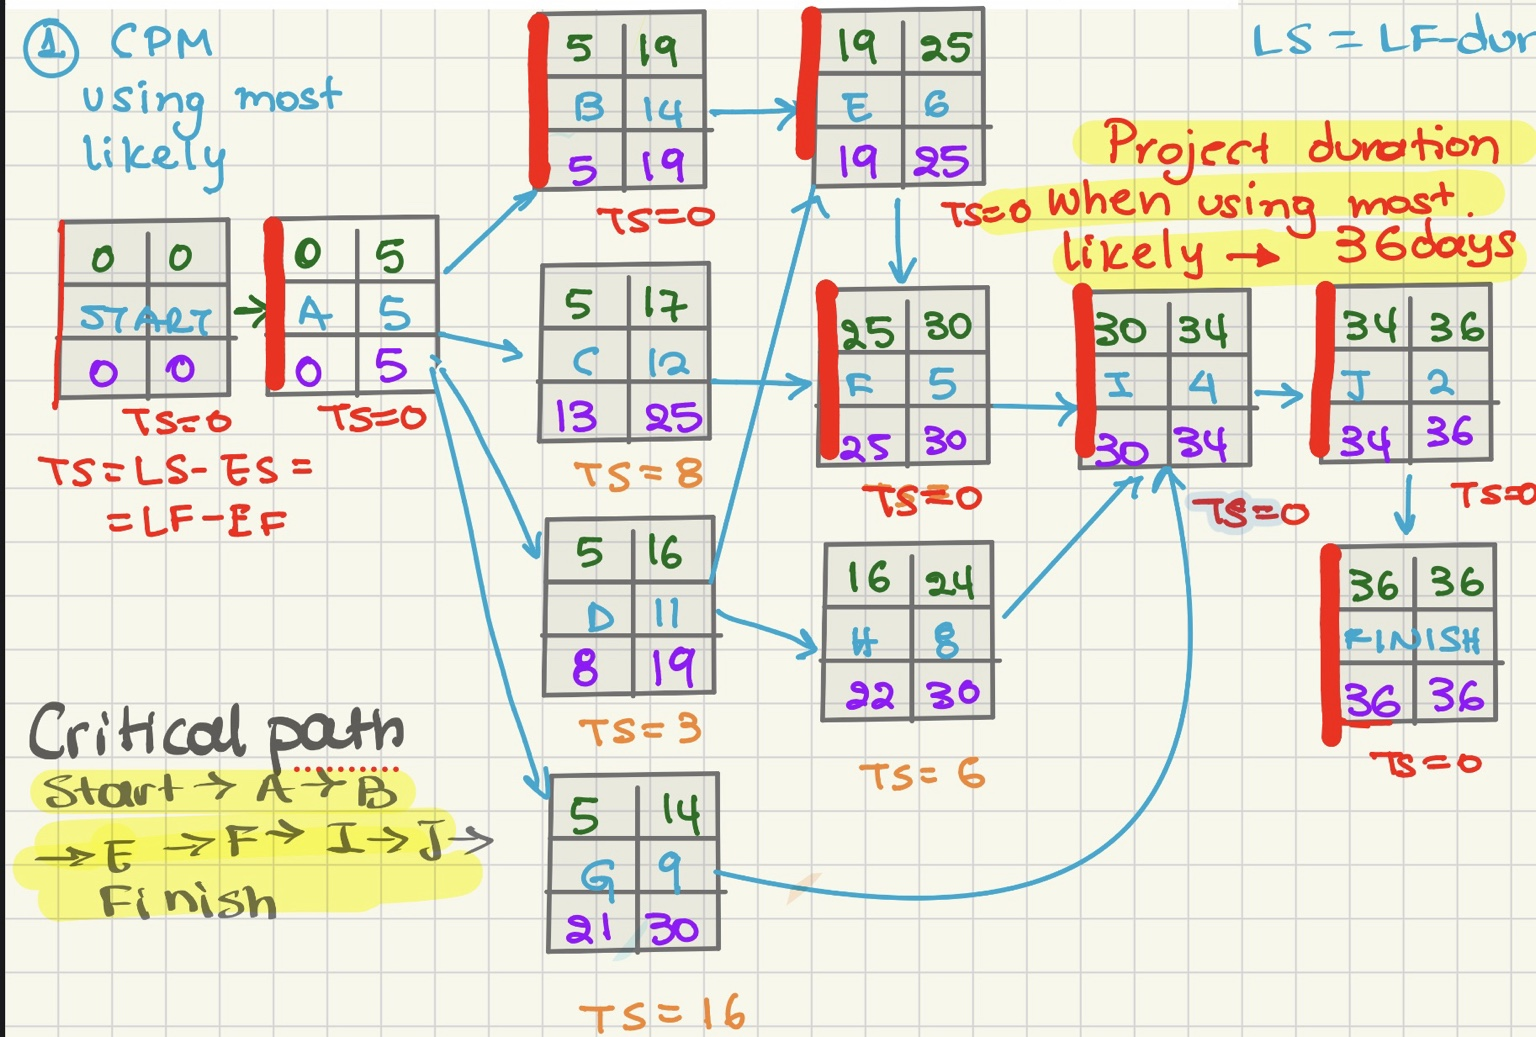

#PERT

In [ ]:
#PERT estimated duration of each activity using the formula (o+4*m+p)/6
def pert_est_duration(o, m, p):
    return (o+4*m+p)/6
for name,description, predecessors,o,m,p in activities:
    print(f"{name}: {pert_est_duration(o, m, p):.2f}")

A: 5.17
B: 15.00
C: 12.67
D: 11.50
E: 6.33
F: 5.33
G: 9.33
H: 8.33
I: 4.17
J: 2.17


Calculate CPM using the expected durations

Critical Path: Start-A-B-E-F-I-J-Finish </br>
Expected project duration 38.17



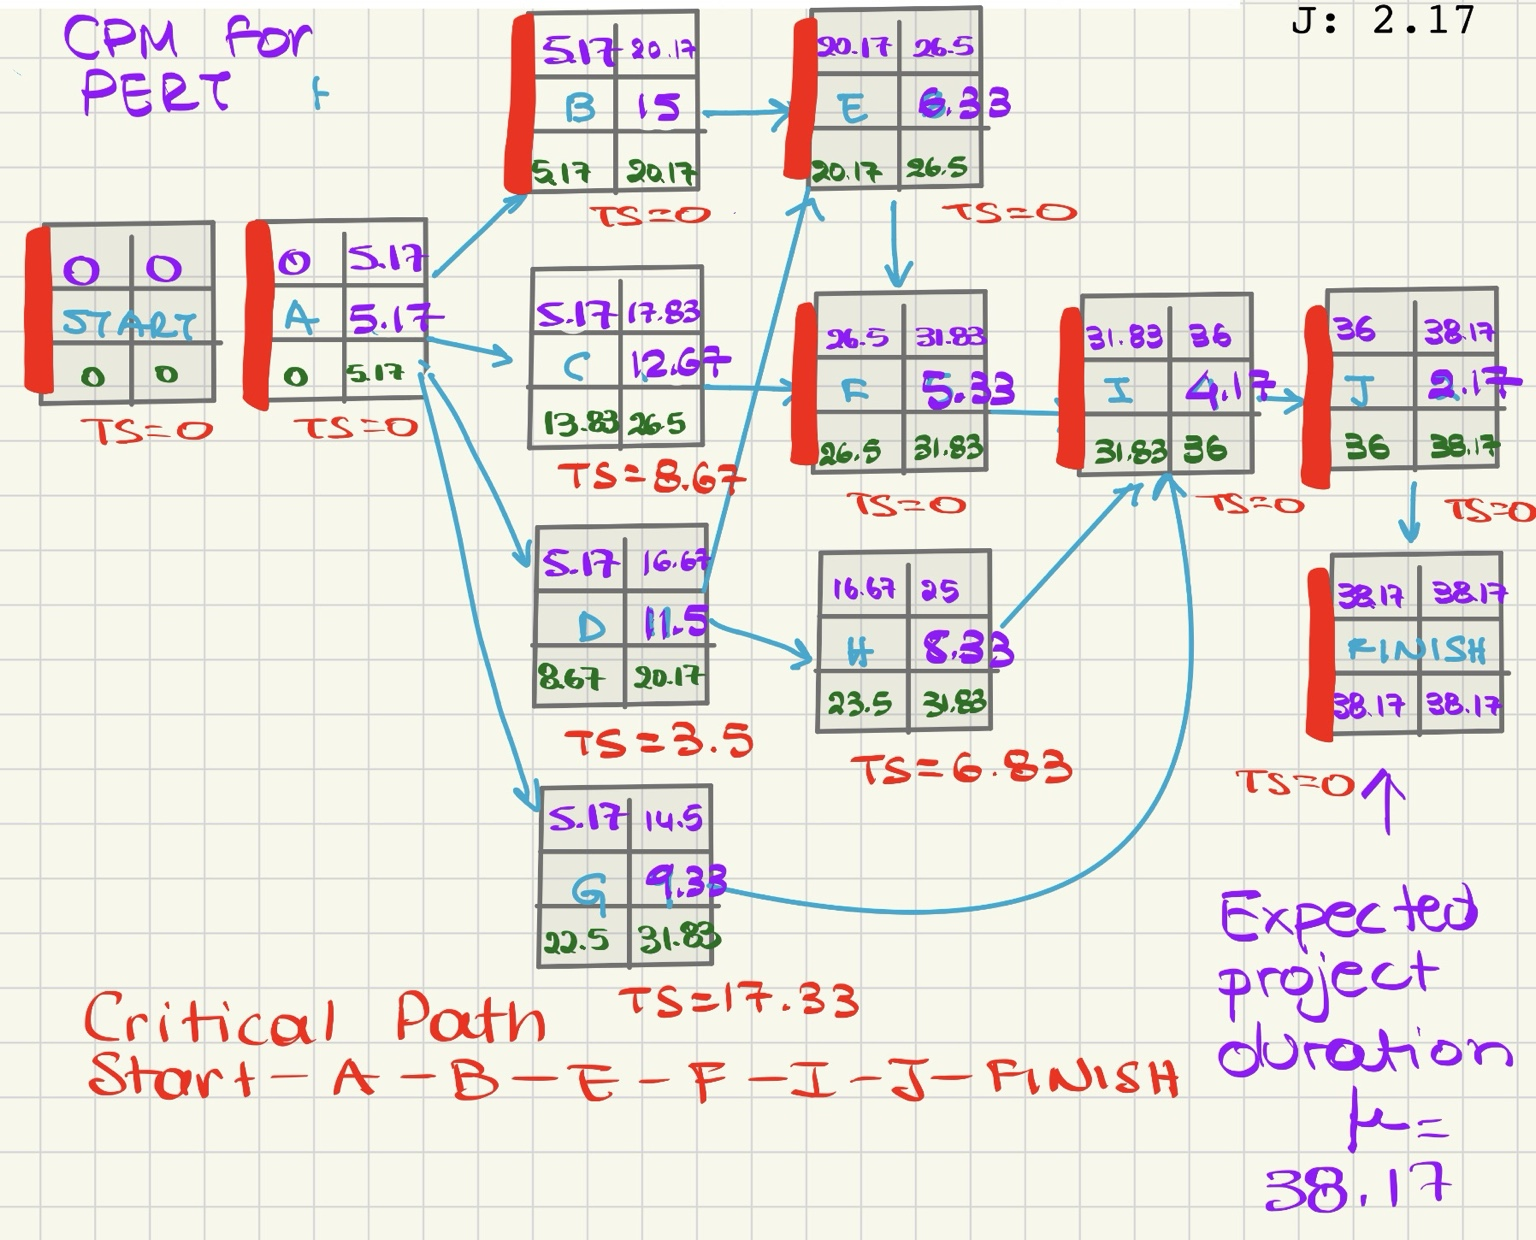

In [ ]:
#We calculate for each critical activity [(p-o)/6]^2

def pert_variance(o, p):
    return ((p-o)/6)**2

for name,description, predecessors,o,m,p in activities:
    print(f"{name}: {pert_variance(o, p):.2f}")

#sum up the pert variance of the project's critical tasks

critical_path=['A','B','E','F','I','J']
critical_path_variance=0
for name,description, predecessors,o,m,p in activities:
    if name in critical_path:
        critical_path_variance+=pert_variance(o, p)
print(f"Critical Path Variance: {critical_path_variance:.2f}")
print(f"Project standard deviation:{critical_path_variance**0.5:.2f}days ")
project_sd=critical_path_variance**0.5

A: 0.69
B: 7.11
C: 4.00
D: 3.36
E: 1.00
F: 1.00
G: 1.78
H: 1.78
I: 0.69
J: 0.25
Critical Path Variance: 10.75
Project standard deviation:3.28days 


### Normal Distribution Functions (`scipy.stats.norm`)

| Function | Official Name | Description |
|---|---|---|
| `norm.cdf()` | **Cumulative Distribution Function (CDF)** | Probability of being **less than or equal to** a value. |
| `norm.sf()` | **Survival Function (SF)** | Probability of **exceeding** a value. |
| `norm.ppf()` | **Percent Point Function (PPF)** | **Inverse of the CDF**; returns the value corresponding to a given cumulative probability. |

In [ ]:
#Using the PERT method calculate the probability of finishing by day 40.
D=40
pert_proj_dur=38.17
z=(D-pert_proj_dur)/project_sd
prob_less=norm.cdf(z)

print(f"P(T <= {D}) = {prob_less:.2%}  (z = {z:.3f})")


P(T <= 40) = 71.16%  (z = 0.558)


In [ ]:
#probability of completing in D days or more
pert_proj_dur=38.17
z=(D-pert_proj_dur)/project_sd
prob_more=norm.sf(z)

print(f"P(T >= {D}) = {prob_more:.2%}  (z = {z:.3f})")


P(T >= 40) = 28.84%  (z = 0.558)


In [ ]:
#PERT duration corresponding to a specific confidence
confidence=0.9
z_conf=norm.ppf(confidence)
promised_day=pert_proj_dur+z_conf*project_sd

print(f"{confidence:.0%} completion day: {promised_day:.2f}")

90% completion day: 42.37


#Monte Carlo
##One draw for handwritten CPM using MC (we chose triangular distribution)

In [ ]:
# Generate ONE triangular duration per activity for the handwritten CPM
np.random.seed(1)
hand_durations = {}
for name, description, previous, a, m, b in activities:
    hand_durations[name] = np.random.triangular(a, m, b)

print("Durations to copy into the handwritten CPM:")
for name, duration in hand_durations.items():
    print(f"{name}: {duration:.2f} days")

Durations to copy into the handwritten CPM:
A: 5.04 days
B: 17.98 days
C: 8.07 days
D: 10.65 days
E: 5.33 days
F: 4.05 days
G: 8.11 days
H: 7.88 days
I: 3.99 days
J: 2.34 days


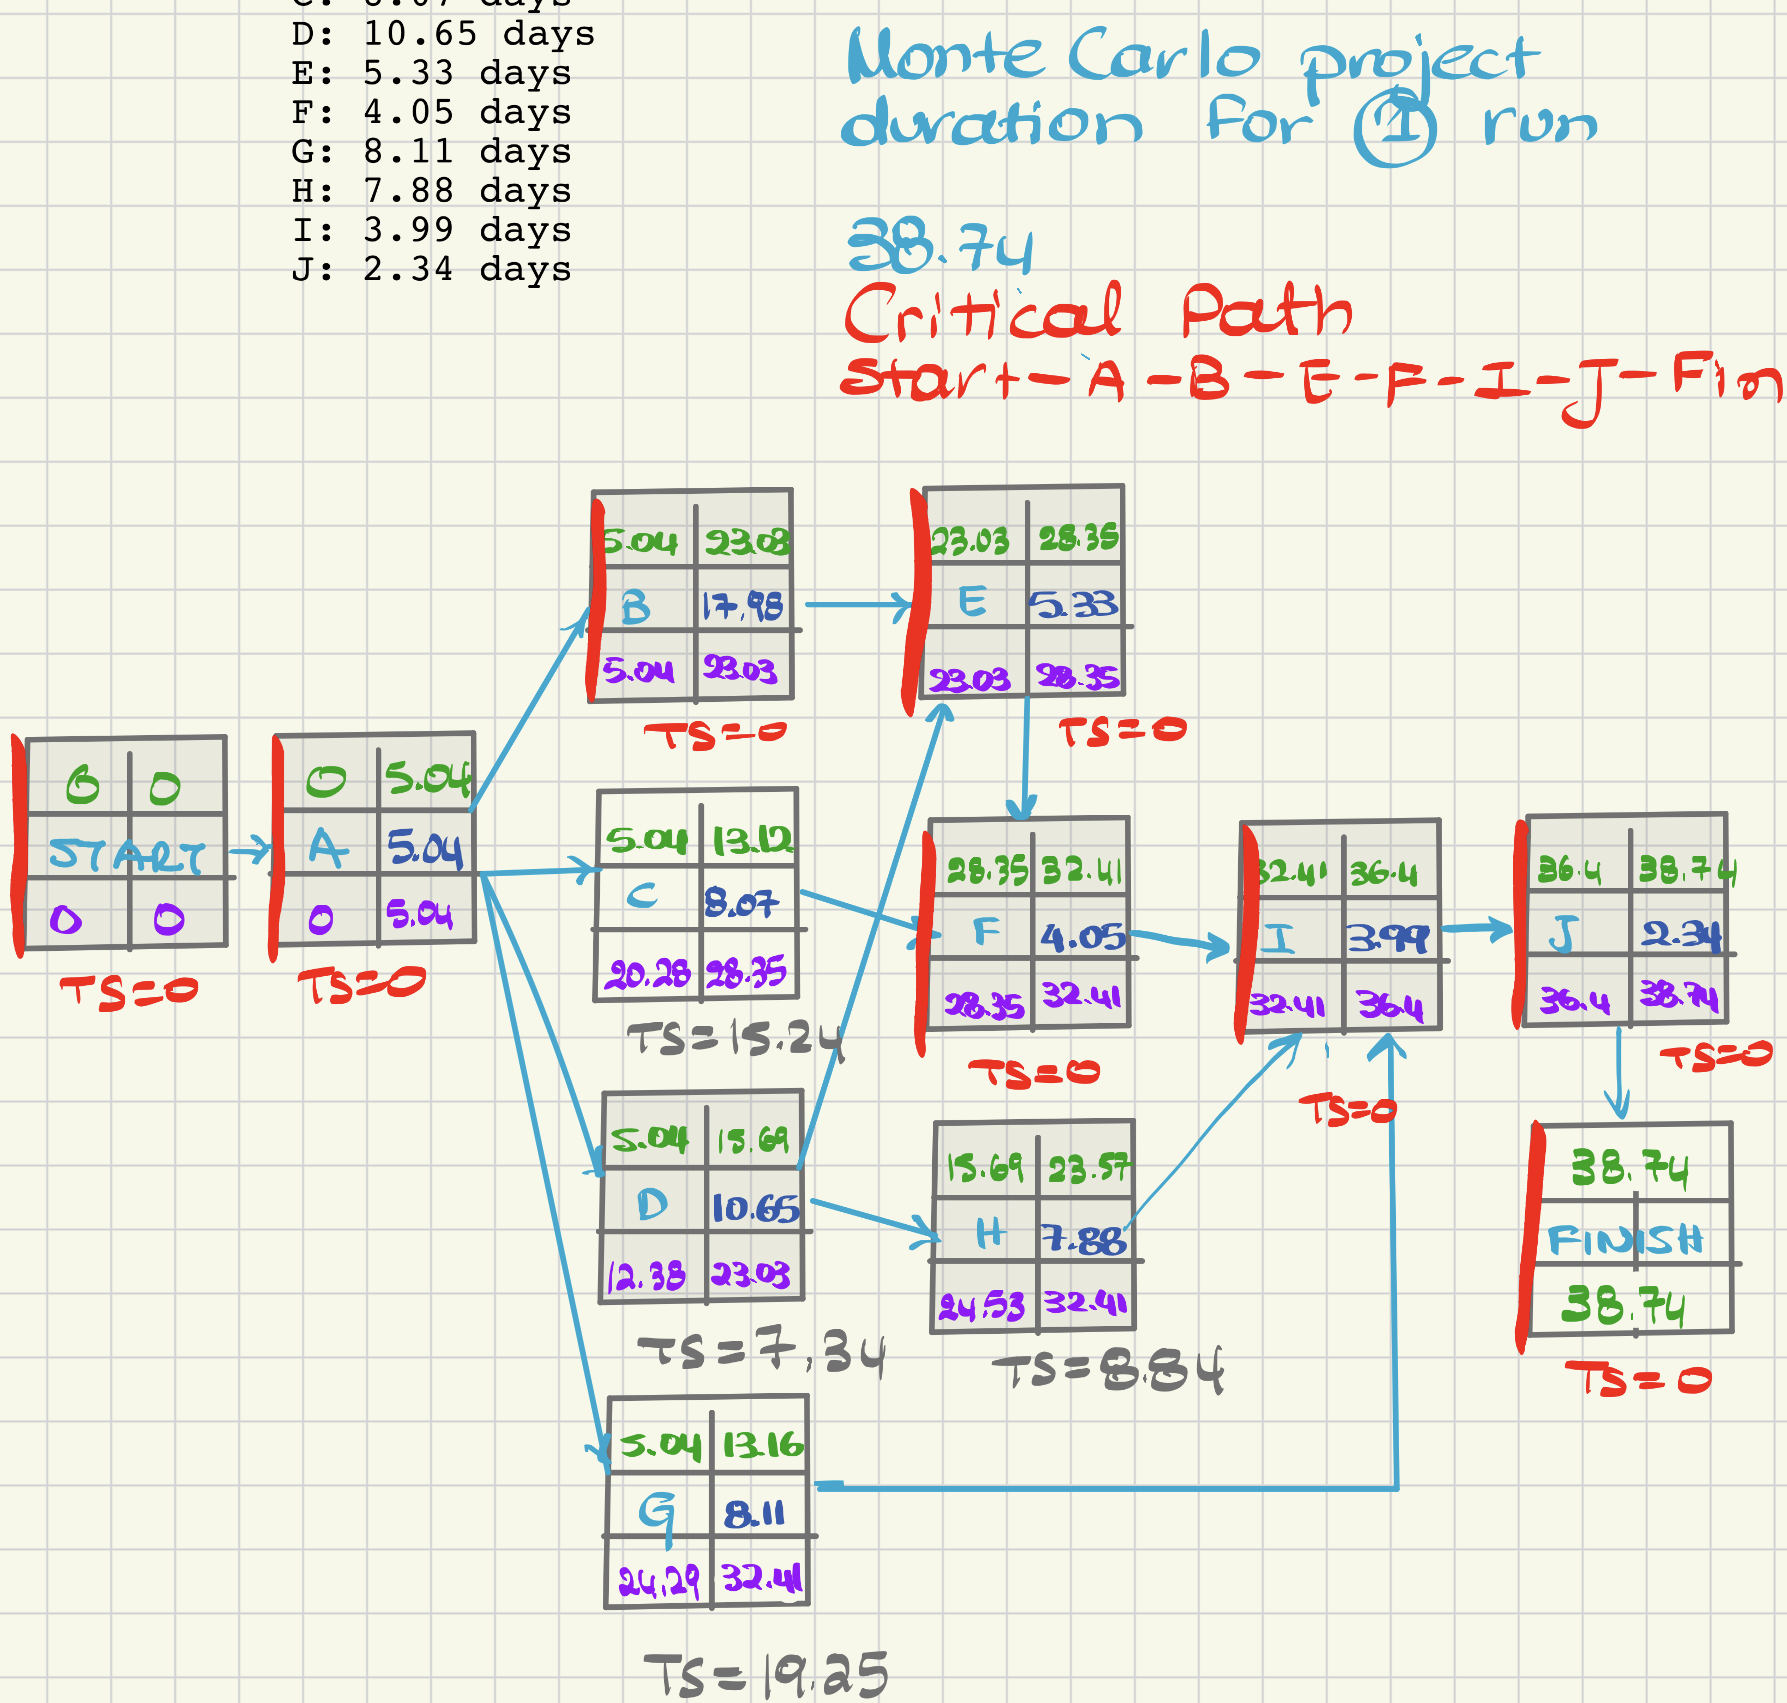

# CPM calculator

In [ ]:
# CPM function
def cpm(activities, duration_type='pert',mc_durations=None, verbose=True):

    # Activity durations
    durations = {}
    preds = {}

    for i, (name, description, predecessors, o, m, p) in enumerate(activities):
        preds[name] = predecessors

        if duration_type == 'o':
            durations[name] = o
        elif duration_type == 'm':
            durations[name] = m
        elif duration_type == 'p':
            durations[name] = p
        elif duration_type == 'pert':
            durations[name] = (o + 4*m + p) / 6
        elif duration_type == 'mc':
            durations[name] = mc_durations[i]

    # Successors
    succs = {
        name: [other for other in preds if name in preds[other]]
        for name in preds
    }

    # FORWARD PASS
    ES = {}
    EF = {}

    while len(EF) < len(activities):
        scheduled = len(EF)

        for name in preds:
            if name in EF:
                continue

            if all(p in EF for p in preds[name]):
                ES[name] = max([EF[p] for p in preds[name]], default=0)
                EF[name] = ES[name] + durations[name]

        if len(EF) == scheduled:
            raise ValueError("Cannot schedule activities. Check predecessors.")

    project_duration = max(EF.values())

    # BACKWARD PASS
    LS = {}
    LF = {}

    while len(LS) < len(activities):
        scheduled = len(LS)

        for name in succs:
            if name in LS:
                continue

            if all(s in LS for s in succs[name]):
                LF[name] = min([LS[s] for s in succs[name]], default=project_duration)
                LS[name] = LF[name] - durations[name]

        if len(LS) == scheduled:
            raise ValueError("Cannot schedule activities. Check successors.")

    # SLACK AND CRITICAL ACTIVITIES
    slack = {name: LS[name] - ES[name] for name in preds}
    critical = [name for name in preds if abs(slack[name]) < 1e-9]

    # RESULTS
    results = pd.DataFrame([
        [name, durations[name], ES[name], EF[name], LS[name], LF[name], slack[name]]
        for name in preds
    ], columns=["Activity", "Duration", "ES", "EF", "LS", "LF", "Slack"])

    if verbose:
        print(f"Project duration: {project_duration:.2f} days")
        print(f"Critical activities: {critical}")
        print(results.round(2).to_string(index=False))

    return project_duration, critical, results

#Monte Carlo Simulation 10,000 replications using triangular distribution for the durations

In [ ]:
#run 10000 MC sim


# Number of simulations
N = 10000

# Store simulation results
project_durations = []
critical_counts = {name: 0 for name, description, predecessors, o, m, p in activities}

# Monte Carlo Simulation
for simulation in range(N):

    # Generate random durations using triangular distributions
    mc_durations = [
        np.random.triangular(o, m, p)
        for name, description, predecessors, o, m, p in activities
    ]

    # Run CPM with the generated durations
    project_duration, critical, results = cpm(
        activities,
        duration_type='mc',
        mc_durations=mc_durations,
        verbose=False
    )

    # Save project duration
    project_durations.append(project_duration)

    # Count how often each activity is critical
    for name in critical:
        critical_counts[name] += 1

# Convert to NumPy array
project_durations = np.array(project_durations)

###Print overall results for MC

In [ ]:
# Calculate and print Monte Carlo simulation results
print(f"Mean Project Duration: {np.mean(project_durations):.2f} days")
print(f"Minimum Project Duration: {np.min(project_durations):.2f} days")
print(f"Maximum Project Duration: {np.max(project_durations):.2f} days")
print(f"Standard Deviation: {np.std(project_durations):.2f} days")
print(f"90th Percentile (90% confident to finish by): {np.percentile(project_durations, 90):.2f} days")
print(f"95th Percentile (95% confident to finish by): {np.percentile(project_durations, 95):.2f} days\n")



Mean Project Duration: 40.68 days
Minimum Project Duration: 28.45 days
Maximum Project Duration: 56.05 days
Standard Deviation: 3.86 days
90th Percentile (90% confident to finish by): 45.95 days
95th Percentile (95% confident to finish by): 47.46 days



#Evaluating the interventions

In [ ]:
# Intervention options
options = {
    1: {'activity': 'B', 'o': 7, 'm': 10, 'p': 16, 'fee': 6000},
    2: {'activity': 'D', 'o': 5, 'm': 8,  'p': 12, 'fee': 4500},
    3: {'activity': 'C', 'o': 6, 'm': 8,  'p': 13, 'fee': 3500}
}

# Simulation parameters
N = 10000
deadline = 40
required_probability = 0.80

# Replace with the actual damages specified in the assignment
damage_per_day = 7500
np.random.seed(1)

# All eight combinations (0 = No, 1 = Yes)
combinations = list(product([0, 1], repeat=3))
summary = []

# Evaluate each combination
for combination in combinations:
    # Selected interventions
    selected = [
        option for option, use in zip(options, combination)
        if use == 1
    ]
    # Upfront fee
    upfront_cost = sum(options[i]['fee'] for i in selected)
    # Create activities with the selected interventions
    new_activities = []
    for name, description, predecessors, o, m, p in activities:
        for option in selected:
            if name == options[option]['activity']:
                o = options[option]['o']
                m = options[option]['m']
                p = options[option]['p']
        new_activities.append(
            (name, description, predecessors, o, m, p)
        )

    # Monte Carlo simulation
    durations = []
    for simulation in range(N):
        # Generate triangular activity durations
        mc_durations = [
            np.random.triangular(o, m, p)
            for name, description, predecessors, o, m, p in new_activities
        ]
        # Recalculate CPM
        project_duration, critical, results = cpm(
            new_activities,
            duration_type='mc',
            mc_durations=mc_durations,
            verbose=False
        )
        durations.append(project_duration)
    durations = np.array(durations)

    # Expected damages
    damages = np.maximum(0, durations - deadline) * damage_per_day
    expected_damages = np.mean(damages)

    # Expected total cost
    expected_total_cost = upfront_cost + expected_damages

    # On-time probability
    on_time = np.mean(durations <= deadline)

    # Save results
    summary.append([
        selected if selected else 'None',
        upfront_cost,
        expected_damages,
        expected_total_cost,
        np.mean(durations),
        on_time,
        np.percentile(durations, 90)
    ])

# RESULTS TABLE
comparison = pd.DataFrame(
    summary,
    columns=[
        'Options',
        'Upfront Fee',
        'Expected Damages',
        'Expected Total Cost',
        'Mean Duration',
        'On-Time Probability',
        '90th Percentile'
    ]
)

print("INTERVENTION COMPARISON")
print(comparison.round(2).to_string(index=False))

INTERVENTION COMPARISON
  Options  Upfront Fee  Expected Damages  Expected Total Cost  Mean Duration  On-Time Probability  90th Percentile
     None            0          14301.51             14301.51          40.68                 0.45            45.95
      [3]         3500          14292.04             17792.04          40.69                 0.45            45.84
      [2]         4500          13677.25             18177.25          40.35                 0.49            45.80
   [2, 3]         8000          13811.69             21811.69          40.40                 0.49            45.91
      [1]         6000           2056.18              8056.18          37.14                 0.83            40.99
   [1, 3]         9500           2085.02             11585.02          37.13                 0.83            40.95
   [1, 2]        10500            693.74             11193.74          35.64                 0.93            39.40
[1, 2, 3]        14000            686.83             146